# B03 表格拟合与残差分析

**在线阅读版／可交互课程源 · 课程修订 P1-1 · 软件核心 0.1.0**

跟随操作：入门；独立解释：基础。先修：代数、单位、读图、均值与平方和。

本课使用**合成解析数据**，不是实验测量，不预测真实反应。完成后应能解释系数、残差、RSS、RMSE及拒绝原因，并保存可重载结果。

阅读：直接看文字、表格和已保存图表；代码无需执行。交互：在安装课程依赖的Jupyter中从头运行，修改“探索参数”后重新运行。GitHub预览本身不运行Python。交互运行请使用本课独立的Colab适配版；其限定环境的运行、表单、保存及用户下载文件已验收，范围见页首。阅读副本本身不是Colab运行入口。

课程包附README_zh-CN.md、samples及wheels；先按导学安装，再运行本课。无需平台令牌、AI密钥或Docker。

## 当前课程状态（2026-10-19）

五课已完成真实Colab默认/修改参数共10轮运行、私有依赖安装、手工参数修改、结果重载及Drive另存副本。五份原生下载的Notebook已核验；其内嵌结果ZIP均与云端结果逐字节一致。单独点击ZIP链接下载仍未验；新RHF仍未验收（NOT_EXECUTED）。

本次仅更新公开导航和状态文字，不改变科学代码、样本、内置wheel及运行器。保存的科学输出和Colab内置原课中的旧状态文字属于历史快照，以本页说明及docs/STATUS.md为准；FAIL、DIAGNOSTIC及NOT_ASSESSED边界不变。

GitHub只显示静态内容；交互计算使用独立Colab适配。公开页面/固定ref入口首次同步后单独核对；Binder、其它账号/环境、试学与独立解释能力未验收。

[课程首页](../README.md) · [交互运行说明](../docs/RUNNING.md) · [完成与未验收范围](../docs/STATUS.md)

## 学习与验收范围

五课已完成真实Colab默认/修改参数共10轮运行、私有依赖安装、手工参数修改、结果重载及Drive另存副本。五份原生下载的Notebook已核验；其内嵌结果ZIP均与云端结果逐字节一致。单独点击ZIP链接下载仍未验；新RHF仍未验收（NOT_EXECUTED）。

本次仅更新公开导航和状态文字，不改变科学代码、样本、内置wheel及运行器。保存的科学输出和Colab内置原课中的旧状态文字属于历史快照，以本页说明及docs/STATUS.md为准；FAIL、DIAGNOSTIC及NOT_ASSESSED边界不变。

GitHub只显示静态内容；交互计算使用独立Colab适配。公开页面/固定ref入口首次同步后单独核对；Binder、其它账号/环境、试学与独立解释能力未验收。

[五课入口](../README.md) · [本课Colab适配](../colab/B03-colab.ipynb)

In [1]:
PREPARE_COLAB = False
if PREPARE_COLAB:
    import hashlib, json, os, subprocess, sys, uuid, zipfile
    from pathlib import Path, PurePosixPath
    from google.colab import files
    if sys.version_info < (3,12):
        raise RuntimeError("本课核心要求Python 3.12或更新版本；当前云端环境未验收。")
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("请选择本课一个ZIP；不要上传私有资料。")
    filename = next(iter(uploaded))
    target = Path("b03-cloud-" + uuid.uuid4().hex)
    target.mkdir(exist_ok=False)
    with zipfile.ZipFile(filename) as z:
        for item in z.infolist():
            name = PurePosixPath(item.filename)
            if name.is_absolute() or ".." in name.parts or ":" in item.filename or "\\" in item.filename or (item.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError("ZIP包含非法路径或链接")
        if sum(i.file_size for i in z.infolist()) > 32*1024*1024:
            raise ValueError("ZIP解包内容超出课程预算")
        z.extractall(target)
    record = json.loads((target / "lesson-manifest.json").read_text("utf-8"))
    for item in record["inputs"] + [record["wheel"]]:
        rel = PurePosixPath(item["file"])
        if rel.is_absolute() or ".." in rel.parts or ":" in item["file"] or "\\" in item["file"]:
            raise ValueError("课程清单路径非法")
        if hashlib.sha256((target / item["file"]).read_bytes()).hexdigest() != item["sha256"]:
            raise ValueError("课程文件哈希不符")
    subprocess.check_call([sys.executable,"-m","pip","install","-r","requirements.txt"], cwd=target)
    os.chdir(target)
    print("课程文件已准备；必要时按Colab提示重启后重新准备。云端验收尚未执行。")
else:
    print("云端安装关闭；本地按导学准备依赖后顺序运行。")

云端安装关闭；本地按导学准备依赖后顺序运行。


## 1. 找到样本并核对来源

在项目中运行，或将课程ZIP解压后从该目录启动Jupyter。只读取课程清单内固定文件，校验SHA-256；不会扫描私有配置或访问网络。每次运行创建新的结果目录，保留此前结果。

In [2]:
import copy, hashlib, json, uuid
from pathlib import Path
import numpy as np
from IPython.display import display, HTML, Image
from ai4orgchem_data_processing.analysis import analyze, run_analysis

roots = [p for base in (Path.cwd(), *Path.cwd().parents)
         for p in (base, base / "learning/table_fitting")
         if (p / "lesson-manifest.json").is_file()]
if not roots:
    raise FileNotFoundError("请从解压后的课程目录或项目目录启动；查看导学。")
lesson_root = roots[0]
manifest = json.loads((lesson_root / "lesson-manifest.json").read_text("utf-8"))
for item in manifest["inputs"]:
    assert hashlib.sha256((lesson_root / item["file"]).read_bytes()).hexdigest() == item["sha256"]
workspace = lesson_root / "outputs" / ("study-" + uuid.uuid4().hex)
workspace.mkdir(parents=True, exist_ok=False)
samples = lesson_root / "samples"
def request(name):
    return json.loads((samples / (name + ".json")).read_text("utf-8"))
def raw(task):
    return json.dumps(task, ensure_ascii=False, allow_nan=False).encode("utf-8")
print("样本完整性：PASS；本次结果使用新的课程内目录。")

样本完整性：PASS；本次结果使用新的课程内目录。


## 2. 先看数据，再选择模型

x无量纲，y单位kJ/mol。F2五个点为(-2,-2)、(-1,-3)、(0,3)、(1,1)、(2,6)。我们按已定义的教学任务采用带截距直线；不自动删点、不改权重、不挑选最漂亮的模型。

$$\hat y=b_0+b_1x,\qquad e_i=y_i-\hat y_i$$

截距单位为kJ/mol；因为x无量纲，斜率单位也是kJ/mol。若x带长度单位，斜率单位应为能量/长度。

In [3]:
task = request("F2")
print("数据来源：SYNTHETIC_ANALYTIC；x：dimensionless；y：kJ/mol")
display(HTML("<table><tr><th>x</th><th>y (kJ/mol)</th></tr>" +
             "".join(f"<tr><td>{x}</td><td>{y}</td></tr>" for x,y in zip(task["data"]["x"],task["data"]["y"])) + "</table>"))

数据来源：SYNTHETIC_ANALYTIC；x：dimensionless；y：kJ/mol


x,y (kJ/mol)
-2,-2
-1,-3
0,3
1,1
2,6


## 3. 拟合与独立可核算基准

F2可写成1+2x加上扰动(1,-2,2,-2,1)。扰动与常数列、x列的内积均为零，因此最小二乘系数仍是(1,2)，不要求残差为零。

$$RSS=\sum_i e_i^2=14,\qquad RMSE=\sqrt{RSS/n}=\sqrt{14/5}$$

本课RMSE分母为n=5；它不同于采用n-p的残差标准误。系数/预测/残差按冻结合同使用atol=rtol=1e-12；零RSS仅用atol=1e-24。

In [4]:
report = run_analysis(raw(task), samples, workspace / "main")
assert report.exit_code == 0 and report.analysis_status == "PASS"
r = report.results
np.testing.assert_allclose(r["coefficients"], [1,2], atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(r["predicted"], [-3,-1,1,3,5], atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(r["residuals"], [1,-2,2,-2,1], atol=1e-12, rtol=1e-12)
assert abs(r["rss"]-14) <= 1e-12 + 1e-12*14
assert abs(r["rmse"]-np.sqrt(14/5)) <= 1e-12 + 1e-12*np.sqrt(14/5)
assert r["rank"] == 2 and r["samples"] == 5
print(f"截距={r['coefficients'][0]:.6g} kJ/mol；斜率={r['coefficients'][1]:.6g} kJ/mol")
print(f"RSS={r['rss']:.6g} (kJ/mol)^2；RMSE={r['rmse']:.6g} kJ/mol；R²={r['r_squared']:.6g}")
display(HTML("<table><tr><th>x</th><th>y</th><th>拟合值</th><th>残差 y−ŷ</th></tr>"+
             "".join(f"<tr><td>{x:g}</td><td>{y:g}</td><td>{p:.6g}</td><td>{e:.6g}</td></tr>" for x,y,p,e in zip(r["x"],r["y"],r["predicted"],r["residuals"]))+"</table>"))

截距=1 kJ/mol；斜率=2 kJ/mol
RSS=14 (kJ/mol)^2；RMSE=1.67332 kJ/mol；R²=0.740741


x,y,拟合值,残差 y−ŷ
-2,-2,-3,1
-1,-3,-1,-2
0,3,1,2
1,1,3,-2
2,6,5,1


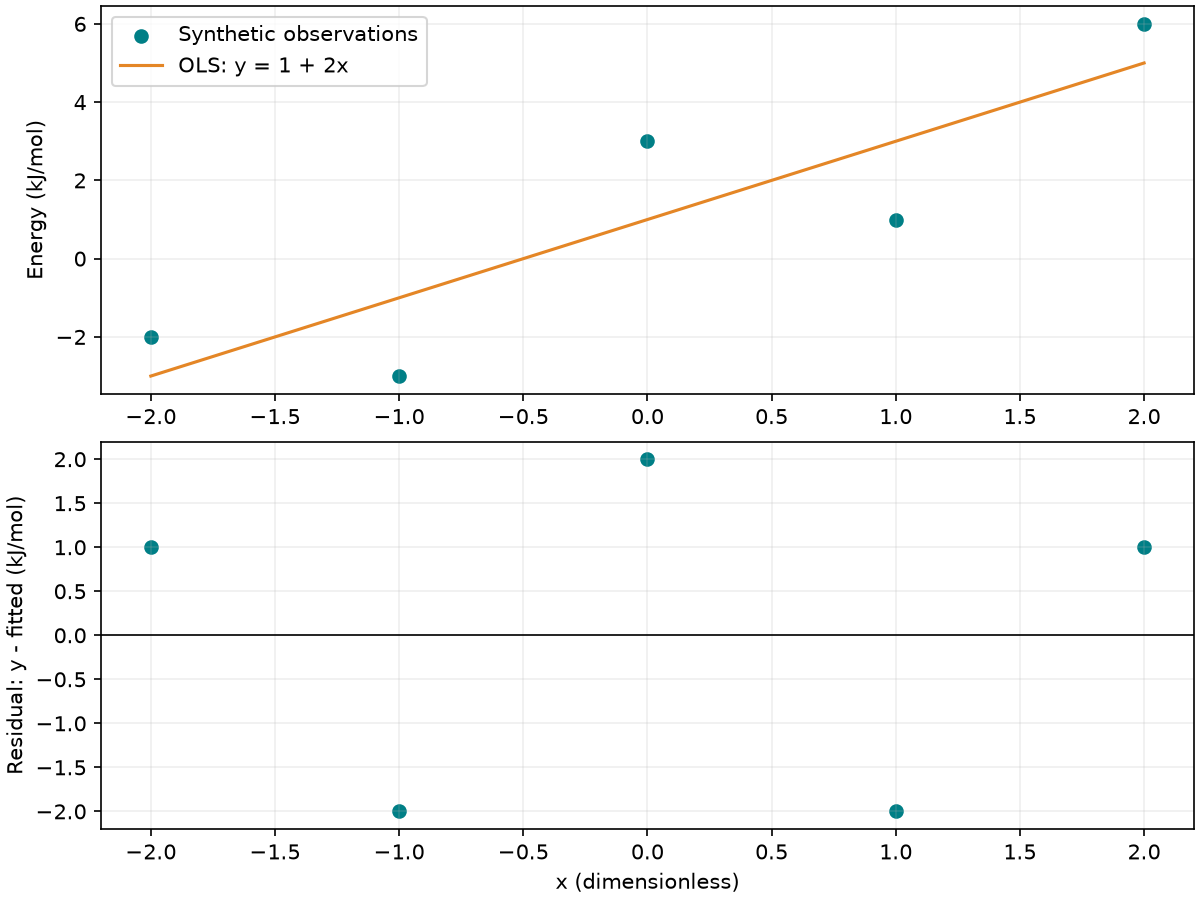

In [5]:
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
fig = Figure(figsize=(8,6), layout="constrained")
FigureCanvasAgg(fig)
top, bottom = fig.subplots(2,1)
top.scatter(r["x"],r["y"],label="Synthetic observations",color="#007f86")
top.plot(r["x"],r["predicted"],label="OLS: y = 1 + 2x",color="#e48626")
top.set_ylabel("Energy (kJ/mol)"); top.legend(); top.grid(alpha=.2)
bottom.scatter(r["x"],r["residuals"],color="#007f86")
bottom.axhline(0,color="black",linewidth=.8)
bottom.set_xlabel("x (dimensionless)"); bottom.set_ylabel("Residual: y - fitted (kJ/mol)")
bottom.grid(alpha=.2)
fig.savefig(workspace / "fit-and-residuals.png",dpi=150)
display(Image(filename=str(workspace / "fit-and-residuals.png")))

图的上半部分比较合成点和拟合线；下半部分展示同一单位下的残差。残差有正有负，不能只看点是否靠近直线。这里只有五个教学点，未做异方差、正态性或独立性检验。

R²约0.740741，表示本样本在带截距定义下的解释比例；不能据此推出因果、机理正确性或样本外精度。本课不计算p值、置信区间或预测区间。

## 4. 精确例和不可定义的指标

F1为1+2x，F3为1+2x+3x²。二次系数按升幂排列，不能混淆顺序。常量y的总离差为零，R²不定义，不把它伪造为0或1。

In [6]:
for name, coefficients, rank in [("F1",[1,2],2),("F3",[1,2,3],3)]:
    result = analyze(raw(request(name)), samples)
    assert result.analysis_status == "PASS"
    np.testing.assert_allclose(result.results["coefficients"], coefficients, atol=1e-12, rtol=1e-12)
    np.testing.assert_allclose(result.results["predicted"], request(name)["data"]["y"], atol=1e-12, rtol=1e-12)
    assert result.results["rss"] <= 1e-24 and result.results["rank"] == rank
    print(name, "解析检查PASS；系数", coefficients)
constant = copy.deepcopy(task); constant["data"]["y"] = [4]*5
constant_result = analyze(raw(constant), samples)
assert constant_result.results["r_squared"] is None
print("常量y：R²未定义（UNDEFINED_CONSTANT_Y）。")

F1

 解析检查PASS；系数 [1, 2]
F3 解析检查PASS；系数 [1, 2, 3]
常量y：R²未定义（UNDEFINED_CONSTANT_Y）。


## 5. 必须拒绝的输入

缺单位、所有x相同、二次拟合只有三点都应拒绝。以下单元逐一核对错误码；拒绝是正确行为，不是允许忽略的异常。

In [7]:
rejections = []
for label, change, expected in [
    ("缺单位", lambda t: t["parameters"].pop("y_unit"), "MISSING_UNIT"),
    ("秩亏", lambda t: t["data"].update(x=[1]*5), "RANK_DEFICIENT"),
    ("样本不足", lambda t: (t["parameters"].update(model="quadratic"),t["data"].update(x=[0,1,2],y=[1,6,17])), "INSUFFICIENT_SAMPLES")]:
    bad = copy.deepcopy(task); change(bad)
    rejected = analyze(raw(bad), samples)
    assert rejected.exit_code == 2 and rejected.analysis_status == "NOT_EXECUTED"
    assert rejected.errors[0]["code"] == expected
    rejections.append(expected)
    print(label + "：按预期拒绝，" + expected)

缺单位：按预期拒绝，MISSING_UNIT
秩亏：按预期拒绝，RANK_DEFICIENT
样本不足：按预期拒绝，INSUFFICIENT_SAMPLES


## 6. 探索参数：自己修改再运行

将Y_SHIFT由0.0改为0.5，再从头运行。它只平移全部y，不改变原样本文件；应预测截距变为1.5，斜率、残差和RSS不变。每次运行写入全新输出目录。

这不是训练/测试划分，也不是泛化验证。

In [8]:
Y_SHIFT = 0.0
assert isinstance(Y_SHIFT,(int,float)) and np.isfinite(Y_SHIFT)
explore = copy.deepcopy(task)
explore["data"]["y"] = [float(v+Y_SHIFT) for v in task["data"]["y"]]
explore["provenance"]["description"] = "合成F2数据全部y平移；不是新实验测量"
explored = run_analysis(raw(explore), samples, workspace / "explore")
assert explored.analysis_status == "PASS"
np.testing.assert_allclose(explored.results["coefficients"], [1+Y_SHIFT,2], atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(explored.results["residuals"], [1,-2,2,-2,1], atol=1e-12, rtol=1e-12)
assert abs(explored.results["rss"]-14) <= 1e-12+1e-12*14
print(f"平移={Y_SHIFT:g}；截距={explored.results['coefficients'][0]:.6g}；斜率={explored.results['coefficients'][1]:.6g}；RSS={explored.results['rss']:.6g}")

平移=0；截距=1；斜率=2；RSS=14


## 7. 保存、校验和重新打开结果

main目录含result.json、table.csv、figure.png/SVG、报告、请求、环境和manifest。下面重新分析保存的请求，核对结果及文件哈希，再生成可下载的ZIP。ZIP留在课程outputs下；Jupyter文件浏览器可右键下载。Colab用户需主动下载，运行时文件不应当作永久保存。

默认不上传或自动下载。执行可选单元时，Colab才会弹出浏览器下载；其它环境直接使用文件浏览器。

In [9]:
import zipfile
saved = workspace / "main"
reloaded = run_analysis((saved / "request.json").read_bytes(), saved / "inputs", workspace / "reload")
assert reloaded.results == report.results and reloaded.analysis_status == report.analysis_status
for item in json.loads((saved / "manifest.json").read_text("utf-8")):
    assert hashlib.sha256((saved / item["file"]).read_bytes()).hexdigest() == item["sha256"]
summary = {"lesson":"B03", "analysis":"PASS", "rejections":rejections,
           "reload_equal":True, "shift":Y_SHIFT, "new_quantum_calls":0,
           "teaching_effectiveness":"NOT_EVALUATED"}
(workspace / "lesson-result.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
archive = workspace / "table-fitting-results.zip"
with zipfile.ZipFile(archive,"x",compression=zipfile.ZIP_DEFLATED) as z:
    for directory in (saved, workspace / "explore"):
        for item in sorted(directory.rglob("*")):
            if item.is_file(): z.write(item,item.relative_to(workspace).as_posix())
    for filename in ["fit-and-residuals.png","lesson-result.json"]:
        z.write(workspace / filename,filename)
assert archive.is_file()
print("已保存：main和explore/的结果；main/ 下的JSON、CSV、图表与报告；table-fitting-results.zip；重载和哈希核对PASS。")
print("新量子计算调用：0；教学效果尚未评价。")

已保存：main和explore/的结果；main/ 下的JSON、CSV、图表与报告；table-fitting-results.zip；重载和哈希核对PASS。
新量子计算调用：0；教学效果尚未评价。


In [10]:
DOWNLOAD_IN_COLAB = False
if DOWNLOAD_IN_COLAB:
    from google.colab import files
    files.download(str(archive))
else:
    print("自动下载关闭；在课程outputs中新建的study目录下载table-fitting-results.zip。")

自动下载关闭；在课程outputs中新建的study目录下载table-fitting-results.zip。


## 8. 解释题与参考答案

先独立回答：①有残差为什么系数不变？②样本多是否保证满秩？③RMSE和残差标准误为何不同？④为何不能由R²断言反应机理？

参考：①本例扰动对设计列正交；②若x无变异，即使记录很多仍秩亏；③本课分别对应n与n-p的分母，需说明估计对象；④本数据为合成描述性例，无独立预测或因果设计。

**练习交付**：把Y_SHIFT改成0.5，写下预期后运行，提交新的Notebook和结果ZIP，并用自己的话说明哪些量改变。自动断言只检验数值，不评价解释能力。

范围：带截距线性/二次OLS；无权重、自动删点、置信区间、训练泛化或任意科学计算。数据与门槛沿用项目冻结合同ADP-IMPLEMENTATION-1.0及adp-numerical-v1；原Notebook保持不变。依赖、数据来源与哈希见课程清单。